# 06 · Real-ESRGAN: enlargement and detail

**What it is.** Two pretrained Real-ESRGAN networks (Wang et al., 2021, BSD-3-Clause): the **compact** `realesr-general-x4v3` (4.7 MB, the default) and the heavy **RRDB x4plus** (64 MB, a slow fallback).

**How it is scored (ground truth).** A sharp public photograph is shrunk to 1/4 size, then enlarged back by (a) plain bicubic interpolation, (b) the compact network, (c) x4plus, and (d) the compact network **blended with bicubic exactly as the application does** (`REALESRGAN_OUTPUT_BLEND`). Compared with the original: PSNR / SSIM / MAE and **sharpness ratio** (Laplacian variance relative to the original, 1.0 = as sharp as the truth), plus time.

**Read this before the numbers.** PSNR and SSIM reward being *close to the pixel values*, which smooth interpolation does very well; a GAN-trained enlarger deliberately adds texture, so it scores *lower* on PSNR/SSIM and *higher* on sharpness. That is a known property of this model family, so both kinds of metric are reported and neither is hidden.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))
from common import *
print("project root:", ROOT)

project root: /Users/Ali/Projects/FaceCloud_backend


In [2]:
from enhancement.hd_restoration import upscale_with_general, upscale_with_realesrgan
blend = float(settings.REALESRGAN_OUTPUT_BLEND); print("application blend with bicubic:", blend)
ids = sorted(public_stock_ids(), key=lambda pk: -sharpness(photo(pk, 800)))[:5]
rows, shown = [], []
for pk in ids:
    truth = photo(pk, 800); small = cv2.resize(truth, (truth.shape[1] // 4, truth.shape[0] // 4), interpolation=cv2.INTER_AREA)
    fit = lambda a: cv2.resize(a, (truth.shape[1], truth.shape[0]), interpolation=cv2.INTER_CUBIC) if a.shape != truth.shape else a
    bicubic = cv2.resize(small, (truth.shape[1], truth.shape[0]), interpolation=cv2.INTER_CUBIC)
    general, t_general = timed(lambda: fit(first(upscale_with_general(small, output_scale=4))))
    heavy, t_heavy = timed(lambda: fit(first(upscale_with_realesrgan(small, output_scale=4))))
    app = cv2.addWeighted(general, blend, bicubic, 1.0 - blend, 0)
    row = {"photo": pk, "sec_compact": round(t_general, 2), "sec_x4plus": round(t_heavy, 2)}
    for name, image in (("bicubic", bicubic), ("compact", general), ("x4plus", heavy), ("app", app)):
        row[f"psnr_{name}"] = round(psnr(truth, image), 2); row[f"ssim_{name}"] = round(ssim(truth, image), 3); row[f"mae_{name}"] = round(mae(truth, image), 2)
        row[f"sharp_{name}"] = round(sharpness(image) / sharpness(truth), 2)
    rows.append(row); shown.append((truth, bicubic, general, heavy, app))
table(rows, ["photo", "psnr_bicubic", "psnr_compact", "psnr_x4plus", "psnr_app", "ssim_bicubic", "ssim_compact", "ssim_x4plus", "ssim_app", "sharp_bicubic", "sharp_compact", "sharp_x4plus", "sharp_app"])

application blend with bicubic: 0.35


photo  psnr_bicubic  psnr_compact  psnr_x4plus  psnr_app  ssim_bicubic  ssim_compact  ssim_x4plus  ssim_app  sharp_bicubic  sharp_compact  sharp_x4plus  sharp_app
-----  ------------  ------------  -----------  --------  ------------  ------------  -----------  --------  -------------  -------------  ------------  ---------
74     19.44         16.88         17.42        18.76     0.843         0.819         0.827        0.843     0.01           0.24           0.21          0.04     
88     28.87         26.55         28.08        29.23     0.842         0.829         0.836        0.851     0.01           0.09           0.07          0.02     
97     28.7          26.86         26.73        28.91     0.866         0.829         0.813        0.868     0.01           0.22           0.51          0.04     
75     33.01         31.41         32.03        33.18     0.799         0.782         0.784        0.799     0.01           0.05           0.05          0.01     
101    31.4          2

bicubic  PSNR  28.28 dB  SSIM 0.846  MAE  5.09  sharpness x0.01
compact  PSNR  25.35 dB  SSIM 0.810  MAE  7.56  sharpness x0.21
x4plus   PSNR  25.95 dB  SSIM 0.806  MAE  7.25  sharpness x0.35
app      PSNR  28.15 dB  SSIM 0.847  MAE  5.37  sharpness x0.04


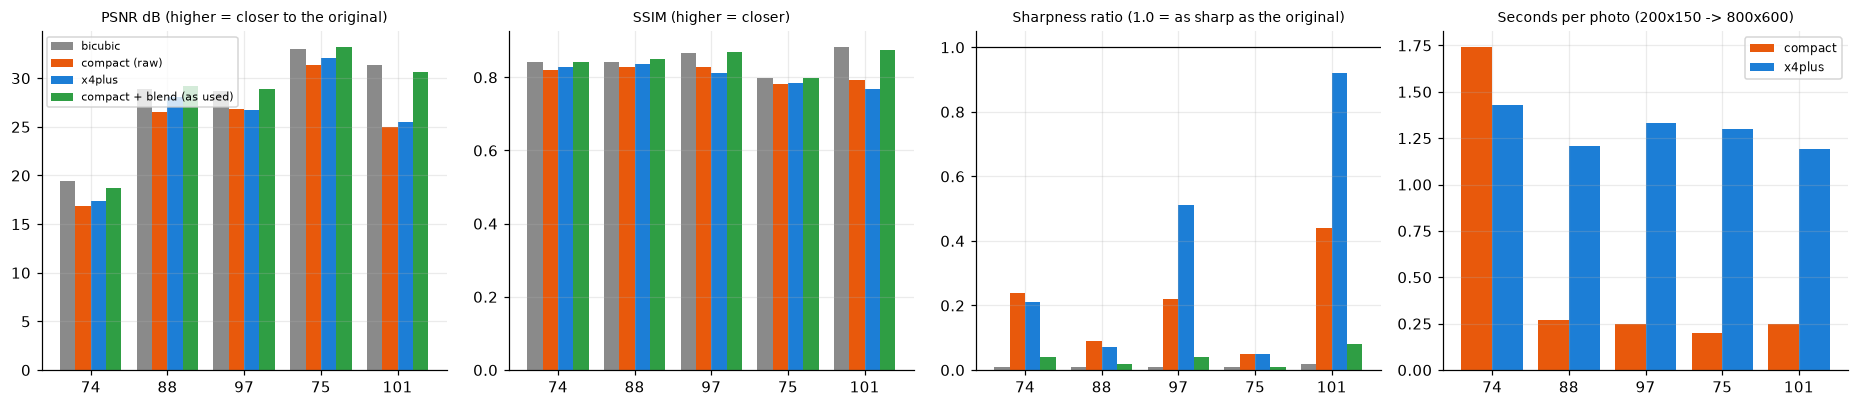

In [3]:
names = ["bicubic", "compact", "x4plus", "app"]; labels = ["bicubic", "compact (raw)", "x4plus", "compact + blend (as used)"]
cols = [COLORS["input"], COLORS["model"], COLORS["baseline"], COLORS["good"]]
fig, ax = plt.subplots(1, 4, figsize=(17, 3.8))
for axis, key, title in ((ax[0], "psnr", "PSNR dB (higher = closer to the original)"), (ax[1], "ssim", "SSIM (higher = closer)"), (ax[2], "sharp", "Sharpness ratio (1.0 = as sharp as the original)")):
    for i, (n, l, c) in enumerate(zip(names, labels, cols)):
        axis.bar(np.arange(len(rows)) + (i - 1.5) * 0.2, [r[f"{key}_{n}"] for r in rows], 0.2, label=l, color=c)
    axis.set_xticks(range(len(rows)), [r["photo"] for r in rows]); axis.set_title(title, fontsize=9)
ax[2].axhline(1.0, color="k", lw=0.8); ax[0].legend(fontsize=7)
ax[3].bar(np.arange(len(rows)) - 0.2, [r["sec_compact"] for r in rows], 0.4, label="compact", color=COLORS["model"]); ax[3].bar(np.arange(len(rows)) + 0.2, [r["sec_x4plus"] for r in rows], 0.4, label="x4plus", color=COLORS["baseline"])
ax[3].set_xticks(range(len(rows)), [r["photo"] for r in rows]); ax[3].set_title("Seconds per photo (200x150 -> 800x600)", fontsize=9); ax[3].legend(fontsize=8)
fig.tight_layout(); save(fig, "06_realesrgan_scores.png")
for n in names: print(f"{n:8s} PSNR {np.mean([r['psnr_' + n] for r in rows]):6.2f} dB  SSIM {np.mean([r['ssim_' + n] for r in rows]):.3f}  MAE {np.mean([r['mae_' + n] for r in rows]):5.2f}  sharpness x{np.mean([r['sharp_' + n] for r in rows]):.2f}")

engines used in the live results: {'detail_restoration/general': 147, 'super_resolution/general': 8, 'super_resolution/realesrgan': 80, 'detail_restoration/ultrasharp': 11, 'detail_restoration/realesrgan': 1}


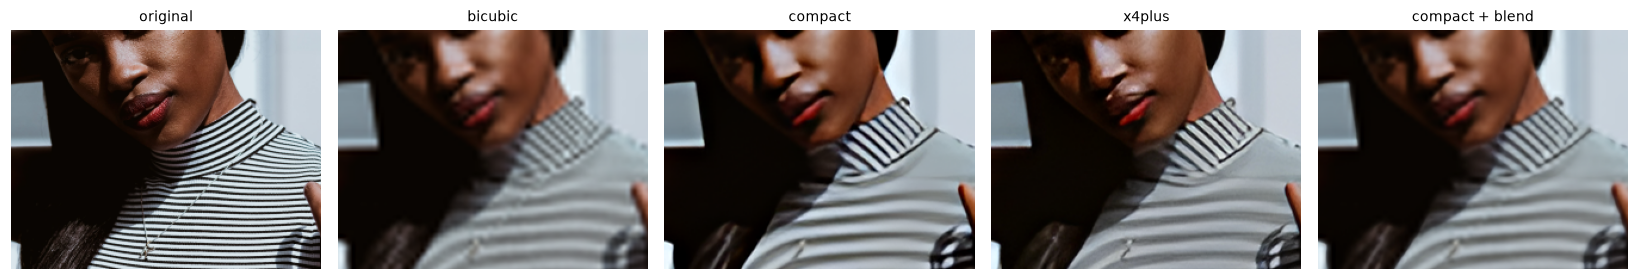

In [4]:
y, x0 = shown[0][0].shape[0] // 3, shown[0][0].shape[1] // 3
crop = lambda i: i[y:y + 200, x0:x0 + 260]
fig = montage([crop(i) for i in shown[0]], ["original", "bicubic", "compact", "x4plus", "compact + blend"], width=3.0); save(fig, "06_realesrgan_examples.png")
from collections import Counter
from enhancement.models import ImageEnhancementResult
run = Counter()
for result in ImageEnhancementResult.objects.filter(status="completed"):
    for stage in (result.applied_parameters.get("adaptive") or {}).get("stages") or []:
        if stage["operation"] in ("super_resolution", "detail_restoration"):
            for engine in stage.get("models_run") or []: run[f"{stage['operation']}/{engine}"] += 1
print("engines used in the live results:", dict(run))
save_json("06_realesrgan.json", {"rows": rows, "pipeline_runs": dict(run)})

## Scorecard (evaluation metrics)

In [5]:
metrics = {"images": len(rows)}
for n in names:
    for k in ("psnr", "ssim", "mae", "sharp"):
        metrics[f"{k}_{n}"] = float(np.mean([r[f"{k}_{n}"] for r in rows]))
metrics["seconds_compact"] = float(np.mean([r["sec_compact"] for r in rows])); metrics["seconds_x4plus"] = float(np.mean([r["sec_x4plus"] for r in rows]))
print(scorecard("Real-ESRGAN", "x4 upscale / detail", metrics, "downscale-then-restore with ground truth, 5 public photos; compact+blend is what the app uses"))

{'task': 'x4 upscale / detail', 'metrics': {'images': 5, 'psnr_bicubic': 28.284, 'ssim_bicubic': 0.8464, 'mae_bicubic': 5.092, 'sharp_bicubic': 0.012, 'psnr_compact': 25.346, 'ssim_compact': 0.8104, 'mae_compact': 7.562, 'sharp_compact': 0.208, 'psnr_x4plus': 25.946, 'ssim_x4plus': 0.8058, 'mae_x4plus': 7.254, 'sharp_x4plus': 0.352, 'psnr_app': 28.148, 'ssim_app': 0.8472, 'mae_app': 5.374, 'sharp_app': 0.038, 'seconds_compact': 0.542, 'seconds_x4plus': 1.292}, 'note': 'downscale-then-restore with ground truth, 5 public photos; compact+blend is what the app uses'}


## Verdict (what the numbers above actually say)
* Against pixel-level ground truth, plain bicubic scores best on PSNR/SSIM/MAE and the networks score lower: they add texture that is plausible but not identical to the original.
* The raw networks recover far more sharpness than bicubic (sharpness ratio about 0.2-0.35 against 0.01; compare the crops) but at lower PSNR/SSIM. The application blends the compact output with bicubic (`REALESRGAN_OUTPUT_BLEND`): the blended version keeps PSNR almost at the bicubic level while adding a little sharpness, i.e. it is the *conservative* setting, trading detail for fidelity (no invented texture on faces).
* The compact network is about twice as fast as x4plus here (and much faster on larger inputs), which is why it is the default.
* The pipeline's own judge (SSIM / structure / identity gates) decides per photograph whether the enlarged version is kept.